<a href="https://colab.research.google.com/github/seoyun333/Linear-Algebra1/blob/main/%EC%84%A0%ED%98%95%EB%8C%80%EC%88%98%ED%95%991_7%EC%A3%BC%EC%B0%A8_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 실습 01

from fractions import Fraction

def print_matrix(M):
    """첨가행렬 출력"""
    for row in M:
        coefficients = " ".join(f"{str(v):>6}" for v in row[:-1])
        print(f"[{coefficients} | {str(row[-1]):>6}]")
    print()


# 문제의 첨가행렬: 마지막 열은 우변 상수
M = [
    [0, -1, -1,  1,  0],
    [1,  1,  1,  1,  6],
    [2,  4,  1, -2, -1],
    [3,  1, -2,  2,  3],
]

# 정확한 분수 계산을 위한 자료형 변환
M = [[Fraction(v) for v in row] for row in M]
n = len(M)

print("초기 첨가행렬")
print_matrix(M)

for col in range(n):
    # 1. 현재 열에서 0이 아닌 피벗을 찾는다.
    pivot_row = next(
        (r for r in range(col, n) if M[r][col] != 0),
        None
    )

    if pivot_row is None:
        raise ValueError("유일한 해가 없습니다.")

    # 2. 피벗이 0이면 아래 행과 교환한다.
    if pivot_row != col:
        M[col], M[pivot_row] = M[pivot_row], M[col]
        print(f"R{col + 1} ↔ R{pivot_row + 1}")
        print_matrix(M)

    # 3. 피벗 행을 피벗 값으로 나누어 피벗을 1로 만든다.
    pivot = M[col][col]

    if pivot != 1:
        M[col] = [v / pivot for v in M[col]]
        print(f"R{col + 1} ← R{col + 1} / ({pivot})")
        print_matrix(M)

    # 4. 피벗 위와 아래의 원소를 모두 0으로 만든다.
    for r in range(n):
        if r == col:
            continue

        factor = M[r][col]

        if factor != 0:
            M[r] = [
                M[r][c] - factor * M[col][c]
                for c in range(n + 1)
            ]

            print(
                f"R{r + 1} ← R{r + 1} "
                f"- ({factor}) × R{col + 1}"
            )
            print_matrix(M)

print("최종 해")
for i in range(n):
    print(f"x{i + 1} = {M[i][-1]}")

초기 첨가행렬
[     0     -1     -1      1 |      0]
[     1      1      1      1 |      6]
[     2      4      1     -2 |     -1]
[     3      1     -2      2 |      3]

R1 ↔ R2
[     1      1      1      1 |      6]
[     0     -1     -1      1 |      0]
[     2      4      1     -2 |     -1]
[     3      1     -2      2 |      3]

R3 ← R3 - (2) × R1
[     1      1      1      1 |      6]
[     0     -1     -1      1 |      0]
[     0      2     -1     -4 |    -13]
[     3      1     -2      2 |      3]

R4 ← R4 - (3) × R1
[     1      1      1      1 |      6]
[     0     -1     -1      1 |      0]
[     0      2     -1     -4 |    -13]
[     0     -2     -5     -1 |    -15]

R2 ← R2 / (-1)
[     1      1      1      1 |      6]
[     0      1      1     -1 |      0]
[     0      2     -1     -4 |    -13]
[     0     -2     -5     -1 |    -15]

R1 ← R1 - (1) × R2
[     1      0      0      2 |      6]
[     0      1      1     -1 |      0]
[     0      2     -1     -4 |    -13]
[     0   

In [6]:
# 실습 02

from fractions import Fraction

def print_matrix(M):
    """첨가행렬 출력"""
    for row in M:
        left = " ".join(f"{str(v):>5}" for v in row[:-1])
        print(f"[{left} | {str(row[-1]):>5}]")
    print()

# 연립방정식
#  x1 - 2x2 +  x3 =  0
#        2x2 - 8x3 =  8
# -4x1 + 5x2 + 9x3 = -9

M = [
    [ 1, -2,  1,  0],
    [ 0,  2, -8,  8],
    [-4,  5,  9, -9],
]

# 분수를 정확하게 계산하기 위한 변환
M = [[Fraction(v) for v in row] for row in M]

print("1. 초기 첨가행렬")
print_matrix(M)

# 세 번째 행의 x1 계수를 0으로 만든다.
M[2] = [M[2][j] + 4 * M[0][j] for j in range(4)]

print("2. R3 ← R3 + 4R1")
print_matrix(M)

# 두 번째 행의 피벗을 1로 만든다.
M[1] = [v / 2 for v in M[1]]

print("3. R2 ← R2 / 2")
print_matrix(M)

# 세 번째 행의 x2 계수를 0으로 만든다.
M[2] = [M[2][j] + 3 * M[1][j] for j in range(4)]

print("4. R3 ← R3 + 3R2 : 삼각형 형태 완성")
print_matrix(M)

# 후진 대입: 마지막 방정식부터 역순으로 계산
n = 3
x = [Fraction(0) for _ in range(n)]

print("5. 후진 대입")

for i in range(n - 1, -1, -1):
    known = sum(M[i][j] * x[j] for j in range(i + 1, n))
    x[i] = (M[i][-1] - known) / M[i][i]
    print(f"x{i + 1} = {x[i]}")

print("\n최종 결과")
for i, value in enumerate(x, start=1):
    print(f"x{i} = {value}")

1. 초기 첨가행렬
[    1    -2     1 |     0]
[    0     2    -8 |     8]
[   -4     5     9 |    -9]

2. R3 ← R3 + 4R1
[    1    -2     1 |     0]
[    0     2    -8 |     8]
[    0    -3    13 |    -9]

3. R2 ← R2 / 2
[    1    -2     1 |     0]
[    0     1    -4 |     4]
[    0    -3    13 |    -9]

4. R3 ← R3 + 3R2 : 삼각형 형태 완성
[    1    -2     1 |     0]
[    0     1    -4 |     4]
[    0     0     1 |     3]

5. 후진 대입
x3 = 3
x2 = 16
x1 = 29

최종 결과
x1 = 29
x2 = 16
x3 = 3


In [8]:
# 실습 03

def print_matrix(M):
    """계수 2열과 각 시스템의 상수항을 구분해 출력"""
    for row in M:
        print(
            f"[{row[0]:>3} {row[1]:>3}"
            f" | {row[2]:>3} | {row[3]:>3}]"
        )
    print()

# 첫 번째 시스템: x1 + 2x2 = 2, 3x1 + 7x2 = 8
# 두 번째 시스템: x1 + 2x2 = 1, 3x1 + 7x2 = 7
#
# 열의 의미: [x1 계수, x2 계수, 첫 번째 우변, 두 번째 우변]
M = [
    [1, 2, 2, 1],
    [3, 7, 8, 7],
]

print("1. 초기 첨가행렬")
print_matrix(M)

# 두 번째 행에서 첫 번째 행의 3배를 뺀다.
M[1] = [M[1][j] - 3 * M[0][j] for j in range(4)]

print("2. R2 ← R2 - 3R1")
print_matrix(M)

# 첫 번째 행에서 두 번째 행의 2배를 뺀다.
M[0] = [M[0][j] - 2 * M[1][j] for j in range(4)]

print("3. R1 ← R1 - 2R2")
print_matrix(M)

# 왼쪽이 단위행렬이 되었으므로 오른쪽 각 열이 해이다.
for system in range(2):
    ocolumn = 2 + system
    x1 = M[0][ocolumn]
    x2 = M[1][ocolumn]

    print(f"시스템 ({system + 1})의 해: x1 = {x1}, x2 = {x2}")

1. 초기 첨가행렬
[  1   2 |   2 |   1]
[  3   7 |   8 |   7]

2. R2 ← R2 - 3R1
[  1   2 |   2 |   1]
[  0   1 |   2 |   4]

3. R1 ← R1 - 2R2
[  1   0 |  -2 |  -7]
[  0   1 |   2 |   4]

시스템 (1)의 해: x1 = -2, x2 = 2
시스템 (2)의 해: x1 = -7, x2 = 4


In [7]:
# 실습 04
from fractions import Fraction

def print_matrix(name, M):
    """행렬을 보기 좋게 출력"""
    print(name)
    for row in M:
        print("[" + " ".join(f"{str(v):>5}" for v in row) + "]")
    print()

# 주어진 행렬
A = [
    [ 1,  2,  1],
    [ 2,  3,  3],
    [-3, -10, 2],
]

n = len(A)

# U는 A의 복사본에서 시작한다.
# Fraction을 사용하여 분수를 정확하게 계산한다.
U = [[Fraction(v) for v in row] for row in A]

# L은 단위행렬에서 시작한다.
L = [
    [Fraction(1 if i == j else 0) for j in range(n)]
    for i in range(n)
]

print_matrix("초기 행렬 A", A)

# 가우스 소거법: 피벗 아래의 원소를 0으로 만든다.
for k in range(n - 1):
    if U[k][k] == 0:
        raise ValueError("피벗이 0이므로 행 교환이 필요합니다.")

    for i in range(k + 1, n):
        # 소거 배수 = 없앨 원소 / 피벗
        multiplier = U[i][k] / U[k][k]

        # 소거 배수를 L에 저장
        L[i][k] = multiplier

        # Ri ← Ri - multiplier × Rk
        U[i] = [
            U[i][j] - multiplier * U[k][j]
            for j in range(n)
        ]

    print(f"R{i + 1} ← R{i + 1} - ({multiplier}) × R{k + 1}")
    print_matrix("현재 U", U)

print_matrix("최종 하삼각행렬 L", L)
print_matrix("최종 상삼각행렬 U", U)

# 행렬 곱 LU 계산
LU = [
    [
        sum(L[i][k] * U[k][j] for k in range(n))
        for j in range(n)
    ]
    for i in range(n)
]

print_matrix("검산: L × U", LU)
print("LU = A 확인:", LU == A)

초기 행렬 A
[    1     2     1]
[    2     3     3]
[   -3   -10     2]

R3 ← R3 - (-3) × R1
현재 U
[    1     2     1]
[    0    -1     1]
[    0    -4     5]

R3 ← R3 - (4) × R2
현재 U
[    1     2     1]
[    0    -1     1]
[    0     0     1]

최종 하삼각행렬 L
[    1     0     0]
[    2     1     0]
[   -3     4     1]

최종 상삼각행렬 U
[    1     2     1]
[    0    -1     1]
[    0     0     1]

검산: L × U
[    1     2     1]
[    2     3     3]
[   -3   -10     2]

LU = A 확인: True


In [9]:
# 실습 05

from fractions import Fraction

def print_matrix(name, M):
    """행렬을 보기 좋게 출력"""
    print(name)
    for row in M:
        print("[" + " ".join(f"{str(v):>5}" for v in row) + "]")
    print()

# 주어진 행렬
A = [
    [ 1,  2,  1],
    [ 2,  3,  3],
    [-3, -10, 2],
]

n = len(A)

# U는 A의 복사본에서 시작한다.
# Fraction을 사용하여 분수를 정확하게 계산한다.
U = [[Fraction(v) for v in row] for row in A]

# L은 단위행렬에서 시작한다.
L = [
    [Fraction(1 if i == j else 0) for j in range(n)]
    for i in range(n)
]

print_matrix("초기 행렬 A", A)

# 가우스 소거법: 피벗 아래의 원소를 0으로 만든다.
for k in range(n - 1):
    if U[k][k] == 0:
        raise ValueError("피벗이 0이므로 행 교환이 필요합니다.")

    for i in range(k + 1, n):
        # 소거 배수 = 없앨 원소 / 피벗
        multiplier = U[i][k] / U[k][k]

        # 소거 배수를 L에 저장
        L[i][k] = multiplier

        # Ri ← Ri - multiplier × Rk
        U[i] = [
            U[i][j] - multiplier * U[k][j]
            for j in range(n)
        ]

    print(f"R{i + 1} ← R{i + 1} - ({multiplier}) × R{k + 1}")
    print_matrix("현재 U", U)

print_matrix("최종 하삼각행렬 L", L)
print_matrix("최종 상삼각행렬 U", U)

# 행렬 곱 LU 계산
LU = [
    [
        sum(L[i][k] * U[k][j] for k in range(n))
        for j in range(n)
    ]
    for i in range(n)
]

print_matrix("검산: L × U", LU)
print("LU = A 확인:", LU == A)

초기 행렬 A
[    1     2     1]
[    2     3     3]
[   -3   -10     2]

R3 ← R3 - (-3) × R1
현재 U
[    1     2     1]
[    0    -1     1]
[    0    -4     5]

R3 ← R3 - (4) × R2
현재 U
[    1     2     1]
[    0    -1     1]
[    0     0     1]

최종 하삼각행렬 L
[    1     0     0]
[    2     1     0]
[   -3     4     1]

최종 상삼각행렬 U
[    1     2     1]
[    0    -1     1]
[    0     0     1]

검산: L × U
[    1     2     1]
[    2     3     3]
[   -3   -10     2]

LU = A 확인: True


회전행렬 A:
[[ 0.5    0.866]
 [-0.866  0.5  ]]

각 꼭짓점의 변환 결과:
P1: (1, 1) → (1.3660, -0.3660)
P2: (1, 2) → (2.2321, 0.1340)
P3: (2, 2) → (2.7321, -0.7321)
P4: (2, 1) → (1.8660, -1.2321)

원점까지의 거리 보존: True


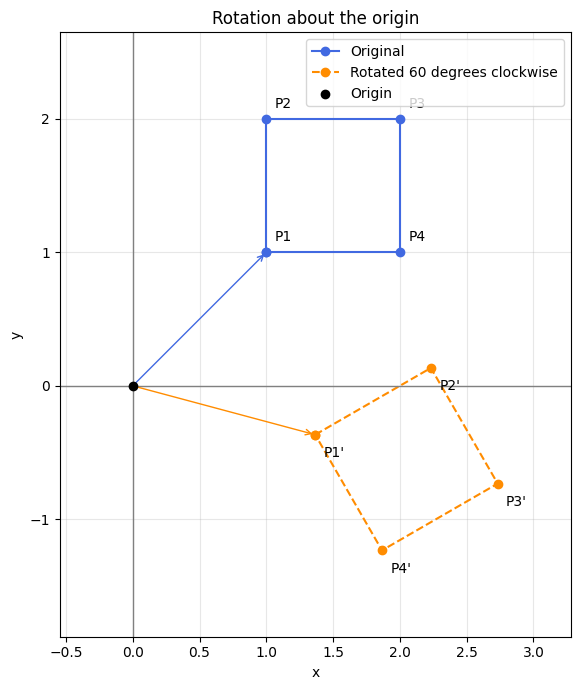

In [10]:
# 실습 06

import numpy as np
import matplotlib.pyplot as plt

# 1. 회전각: 도(degree)를 라디안으로 변환
theta_deg = 60
theta = np.deg2rad(theta_deg)

# 2. 시계 방향 회전행렬
A = np.array([
    [np.cos(theta), np.sin(theta)],
    [-np.sin(theta), np.cos(theta)]
])

# 3. 각 열이 하나의 꼭짓점인 2×4 행렬
# P1=(1,1), P2=(1,2), P3=(2,2), P4=(2,1)
P = np.array([
    [1, 1, 2, 2],
    [1, 2, 2, 1]
], dtype=float)

# 4. 네 꼭짓점을 한 번에 변환
# (2×2) @ (2×4) = (2×4)
Q = A @ P

np.set_printoptions(precision=4, suppress=True)

print("회전행렬 A:")
print(A)

print("\n각 꼭짓점의 변환 결과:")
for i in range(P.shape[1]):
    print(
        f"P{i + 1}: ({P[0, i]:.0f}, {P[1, i]:.0f})"
        f" → ({Q[0, i]:.4f}, {Q[1, i]:.4f})"
    )

# 5. 원점에서 각 꼭짓점까지의 거리 보존 확인
before = np.linalg.norm(P, axis=0)
after = np.linalg.norm(Q, axis=0)

print("\n원점까지의 거리 보존:", np.allclose(before, after))

# 6. 첫 꼭짓점을 끝에 추가하여 닫힌 사각형으로 그린다.
P_closed = np.column_stack((P, P[:, 0]))
Q_closed = np.column_stack((Q, Q[:, 0]))
fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    P_closed[0], P_closed[1],
    "o-", color="royalblue", label="Original"
)
ax.plot(
    Q_closed[0], Q_closed[1],
    "o--", color="darkorange",
    label=f"Rotated {theta_deg} degrees clockwise"
)

# 꼭짓점 이름 표시
for i in range(P.shape[1]):
    ax.annotate(
        f"P{i + 1}", P[:, i],
        xytext=(6, 8), textcoords="offset points"
    )
    ax.annotate(
        f"P{i + 1}'", Q[:, i],
        xytext=(6, -16), textcoords="offset points"
    )

# 원점에서 첫 꼭짓점으로 향하는 벡터 표시
for point, color in [(P[:, 0], "royalblue"), (Q[:, 0], "darkorange")]:
    ax.annotate(
        "", xy=point, xytext=(0, 0),
        arrowprops=dict(arrowstyle="->", color=color)
    )

ax.axhline(0, color="gray", linewidth=1)
ax.axvline(0, color="gray", linewidth=1)
ax.scatter(0, 0, color="black", zorder=5, label="Origin")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Rotation about the origin")
ax.set_aspect("equal", adjustable="box")  # 가로·세로 눈금 비율 동일
ax.margins(0.2)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()